<a href="https://colab.research.google.com/github/MajedMMH/Student-Behaviour-CNN/blob/main/Student_Behaviour_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import PIL
import pathlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

tf.random.set_seed(42)

# 1. Business Understanding

# 2. Data Understanding

In [2]:
dataset_url = "https://drive.usercontent.google.com/download?id=1Ax29bNB54fXodYJ1KIjSuHVR9_k1jRHP&export=download&confirm=t"
tf.keras.utils.get_file('student_behaviour.zip', origin=dataset_url, cache_dir='.', extract=True)

72719741/72719741 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


'./datasets/student_behaviour_extracted'

In [3]:
data_dir = pathlib.Path('/content/datasets/student_behaviour_extracted/student_behaviour')
data_dir

PosixPath('/content/datasets/student_behaviour_extracted/student_behaviour')

In [4]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

23429


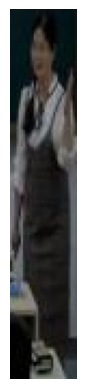

In [5]:
hand_raising_images = list(data_dir.glob('hand-raising/*'))
plt.imshow(PIL.Image.open(hand_raising_images[0]))
plt.axis('off')
plt.show()

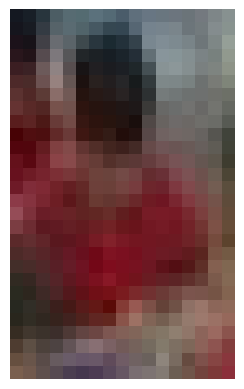

In [6]:
reading_images = list(data_dir.glob('reading/*'))
plt.imshow(PIL.Image.open(reading_images[1]))
plt.axis('off')
plt.show()

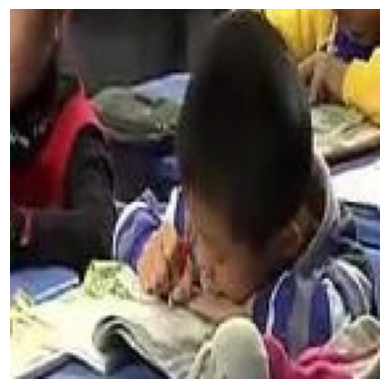

In [7]:
writing_images = list(data_dir.glob('writing/*'))
plt.imshow(PIL.Image.open(writing_images[1]))
plt.axis('off')
plt.show()

In [8]:
print(len(hand_raising_images), len(reading_images), len(writing_images))

10364 9573 3492


# 3. Data Preparation

In [9]:
behaviour_images = {
    'hand-raising': hand_raising_images,
    'reading': reading_images,
    'writing': writing_images,
}

In [10]:
behaviour_labels = {
    'hand-raising': 0,
    'reading': 1,
    'writing': 2,
}

In [11]:
cv2.imread(str(hand_raising_images[0])).shape

(172, 31, 3)

In [15]:
X, y = [], []

for behaviour, image_paths in behaviour_images.items():
    for image_path in image_paths:
        img = cv2.imread(str(image_path))
        X.append(cv2.resize(img, (64, 64)))
        y.append(behaviour_labels[behaviour])

In [16]:
X = np.array(X)
y = np.array(y)

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [19]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

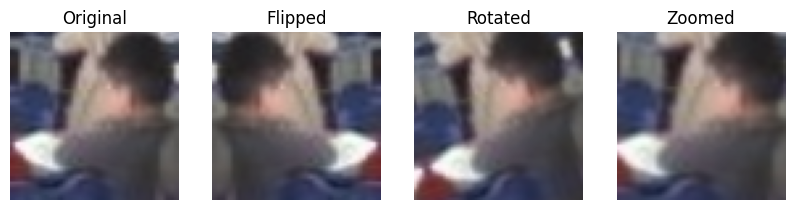

In [20]:
flipped = layers.RandomFlip("horizontal", seed=3)(X_train[:1], training=True)
rotated = layers.RandomRotation(0.1, seed=7)(X_train[:1], training=True)
zoomed = layers.RandomZoom(0.1, seed=5)(X_train[:1], training=True)

images = [X_train[0], flipped[0], rotated[0], zoomed[0]]
titles = ['Original', 'Flipped', 'Rotated', 'Zoomed']
plt.figure(figsize=(10, 3))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(np.array(images[i]).astype('uint8')[:, :, ::-1])
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# 4. Modeling
Reference: [Flower CNN notebook](https://colab.research.google.com/drive/1VDc_TOCuG4eJ45Idv4aEYQDUQ2Yu7Rfp) — follow its model cells, from "Build convolutional neural network" to the end.
Changes: input shape `(64, 64, 3)` and last layer `Dense(3, activation='softmax')`. `data_augmentation` is already defined in section 3.

# 5. Evaluation
Reference: [CIFAR-10 CNN notebook](https://colab.research.google.com/drive/190WdgRLeIyUbzQ0Ir0mEEAWPggmSosBg) — follow its last cells: `evaluate`, `predict`, `confusion_matrix`, `ConfusionMatrixDisplay` and `classification_report`.
Use the best model from section 4 with `X_test_scaled` and `y_test`.

# 6. Deployment
Reference: [Dogs vs Cats notebook](https://colab.research.google.com/drive/1ltb3NNJZvbMNHej17tDSdC-uYWI6izKF) — follow its "Predictive System" cell (last cell).
Read a new image, resize it to 64×64, scale it, predict, and print the class name.